# Data Downlad (GlassPy)

In [2]:
from glasspy.data import SciGlass, sciglass_dbinfo

all_properties_except_Density = SciGlass.available_properties()
all_properties_except_Density.remove("Density293K")

config_el = {
    "drop": [],
    "final_sum": 100
}

config_prop = {
    "keep": ["Density293K"],
    "drop": all_properties_except_Density,
}

config_comp = {
    "final_sum": 100,
}

source = SciGlass(
    elements_cfg=config_el,
    properties_cfg=config_prop,
    compounds_cfg=config_comp,
    metadata=False,  
    autocleanup=True 
)

df = source.data

print('No glasses: '+str(len(df)))

No glasses: 98453


# Data Cleaning

## Removing glasses containing H 

In [3]:
df=df[df['elements']['H']==0]
print('No glasses: '+str(len(df)))

No glasses: 97499


## Oxygen distribution

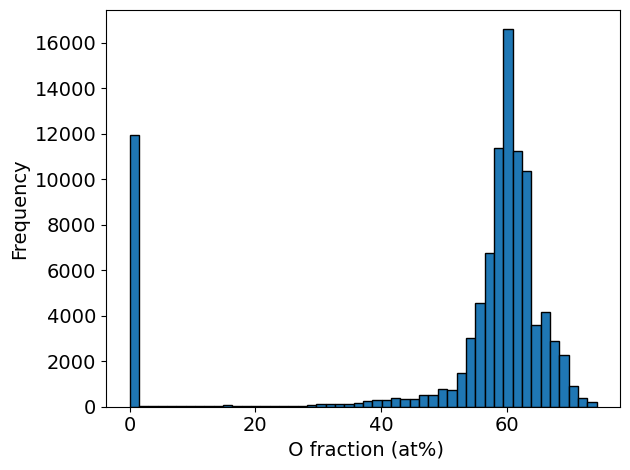

In [4]:
import matplotlib.pyplot as plt

plt.hist(df['elements']['O'], bins=50, edgecolor='black') 
plt.xlabel(r' O fraction (at%)', fontsize=14) 
plt.ylabel('Frequency', fontsize=14) 
plt.tick_params(axis='both', which='major', labelsize=14)
plt.tight_layout()
#plt.grid(True)
plt.show()

### Removing glasses with O < 30 at. %

No glasses: 84860


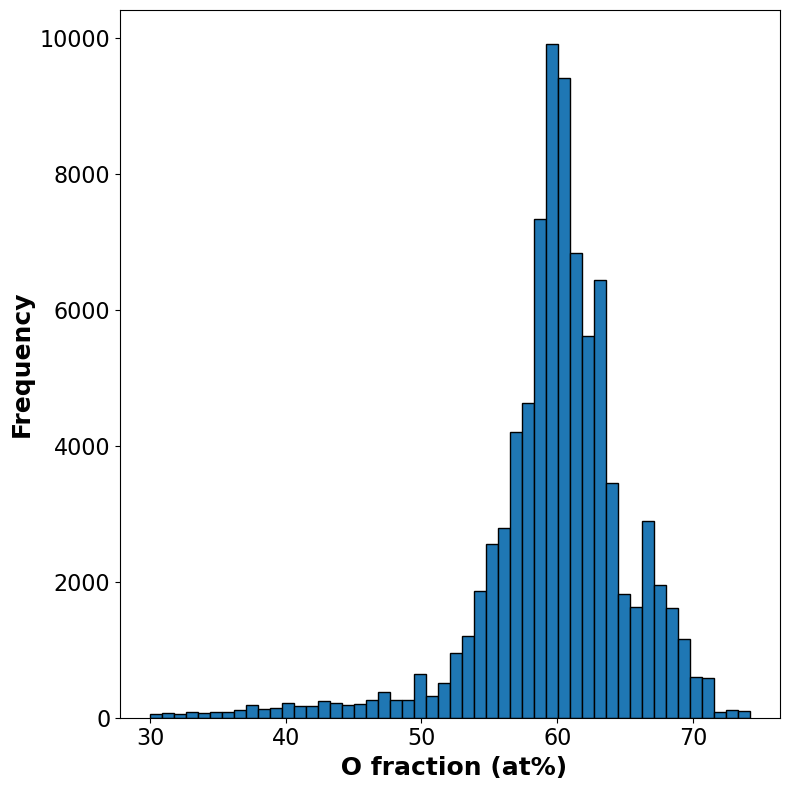

In [14]:
df=df[df['elements']['O']>30]
print('No glasses: '+str(len(df)))

plt.figure(figsize=(8, 8))
plt.hist(df['elements']['O'], bins=50, edgecolor='black') 
plt.xlabel(r' O fraction (at%)', fontsize=18, fontweight='bold') 
plt.ylabel('Frequency', fontsize=18, fontweight='bold') 
plt.tick_params(axis='both', which='major', labelsize=16)
plt.tight_layout()
plt.savefig('Fig1a', dpi=300)
plt.show()

# Changing glass composition to object Composition (pymatgen)

In [18]:
from pymatgen.core import Composition
import pandas as pd

comp=[]

for index, row in df['elements'].iterrows():
    comp.append(Composition(row.to_dict()))

df_glass=pd.DataFrame()
df_glass['composition']=comp
#df_glass['Tg']=df['property'].reset_index(drop=True)

df_glass

,composition
0,"(Li, O, Na, Si, K, Ge, Zr)"
1,"(Li, O, Na, Si, K, Ge, Zr, Ta)"
2,"(Li, O, Na, Si, K, Ge, Zr, Ta)"
3,"(Li, O, Na, Si, K, Ge, Zr, Ta)"
4,"(Li, O, Na, Si, K, Ge, Zr, Ta)"
...,...
84855,"(O, Mg, Al, Si, Ca, Y, Sn)"
84856,"(O, Mg, Al, Si, Ca, Y, Sn)"
84857,"(B, O, Mg, Al, Si, Ca, Sr, Zr, Sn, Ba)"
84858,"(O, Al, Si, Ca, Sr, Zr, Sn, Ba)"


# Adding labels (Density)

In [19]:
df_glass['Density']=df['property'].reset_index(drop=True)
df_glass

,composition,Density
0,"(Li, O, Na, Si, K, Ge, Zr)",2.820
1,"(Li, O, Na, Si, K, Ge, Zr, Ta)",2.918
2,"(Li, O, Na, Si, K, Ge, Zr, Ta)",3.482
3,"(Li, O, Na, Si, K, Ge, Zr, Ta)",3.893
4,"(Li, O, Na, Si, K, Ge, Zr, Ta)",4.335
...,...,...
84855,"(O, Mg, Al, Si, Ca, Y, Sn)",2.835
84856,"(O, Mg, Al, Si, Ca, Y, Sn)",2.785
84857,"(B, O, Mg, Al, Si, Ca, Sr, Zr, Sn, Ba)",2.617
84858,"(O, Al, Si, Ca, Sr, Zr, Sn, Ba)",2.686


# Removing density outliers (95%)

No glasses: 76593


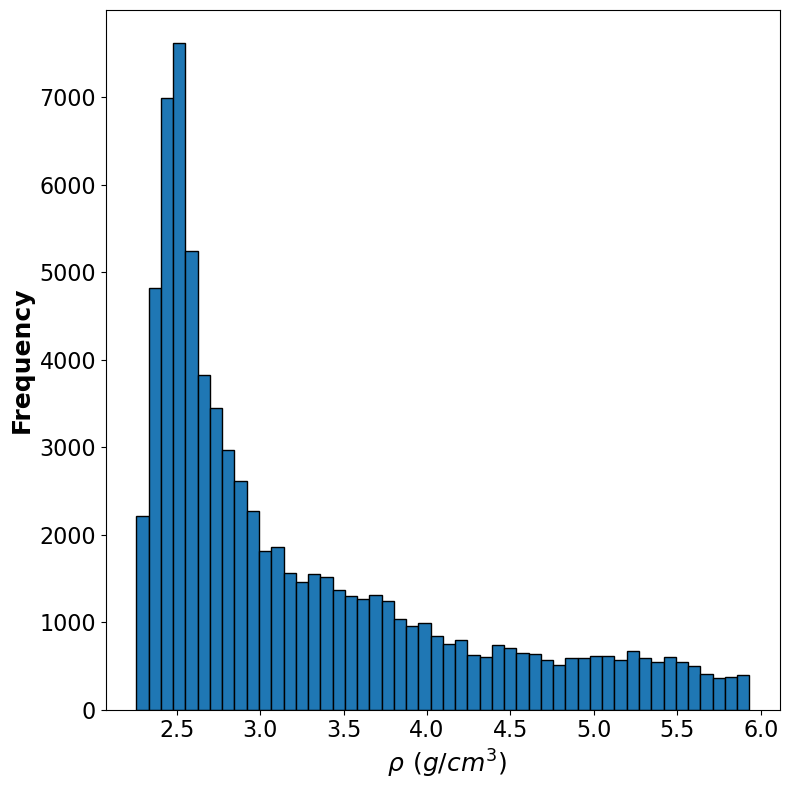

In [21]:
lower_bound = df_glass['Density'].quantile(0.025)  # 2.5 percentile
upper_bound = df_glass['Density'].quantile(0.975)  # 97.5 percentile

# Filtrowanie wartości pomiędzy tymi granicami
df_glass = df_glass[(df_glass['Density'] >= lower_bound) & (df_glass['Density'] <= upper_bound)]

print('No glasses: '+str(len(df_glass)))

plt.figure(figsize=(8, 8))
plt.hist(df_glass['Density'], bins=50, edgecolor='black') 
plt.xlabel(r' $\rho$ $(g/cm^3)$', fontsize=18, fontweight='bold') 
plt.ylabel('Frequency', fontsize=18, fontweight='bold') 
plt.tick_params(axis='both', which='major', labelsize=16)
plt.tight_layout()
plt.savefig('Fig1b', dpi=300)
plt.show()

# Saving csv file

In [26]:
df_glass.to_csv('./data/data_cleaned.csv', index=False)